---
title: Analysis of Explicit Songs
author: George Dokken
date: today
---

## **Can we see shifts in the amount of explicit songs? Or in the reason for being rated explicit?**

We will look at the total amount of explicit songs and how the reason for explicit ratings change over time. The main dataset used will be *Billboard Hot 100 Number Ones* (documentation [here](https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-08-26/readme.md)), specifically the columns `explicit`, `lyrics`, and `lyrical_topic`.

We begin be importing our libraries. We used `pandas` for reading in and manipulating dataframes, as well as `pyplot` and `seaborn` to graph our data. 

In [46]:
# import statements
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data Overview

We read in and begin EDA for our dataset. There are 105 columns, so we use the documentation instead of listing them all below. 

In [48]:
# read in dataframe, look at columns
df = pd.read_csv('data/billboard.csv')
df.columns

Index(['song', 'artist', 'date', 'weeks_at_number_one', 'non_consecutive',
       'rating_1', 'rating_2', 'rating_3', 'overall_rating', 'divisiveness',
       ...
       'featured_in_a_then_contemporary_play', 'written_for_a_film',
       'featured_in_a_then_contemporary_film', 'written_for_a_t_v_show',
       'featured_in_a_then_contemporary_t_v_show', 'associated_with_dance',
       'topped_the_charts_by_multiple_artist', 'double_a_side',
       'eurovision_entry', 'u_s_artwork'],
      dtype='str', length=105)

We subset our dataframe to only include the columns we will use for analysis, including the sing titles and artists, date, explicit status, and lyrical information. We look at the first few rows of of our dataframe. We call the new dataframe `ex`.

In [49]:
# subset dataframe to relevant columns
ex = df[['song', 'artist', 'date', 'weeks_at_number_one', 'explicit', 'lyrics', 'lyrical_topic']]
ex.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love


Taking a look at the `explicit` column reveals that 940 non-explicit songs and 237 explicit ones have ever reached the #1 spot.

In [51]:
# explicit column counts
ex['explicit'].value_counts()

explicit
0    940
1    237
Name: count, dtype: int64

We create two new columns for the year and decade when the song first reached #1 and verify that they look correct.

In [52]:
# create year and decade columns
ex['year'] = ex['date'].str[:4]
ex['decade'] = (ex['year'].astype(int) // 10) * 10
ex.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love,1958,1950
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming,1958,1950
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love,1958,1950
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love,1958,1950
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love,1958,1950


Note: We will need to engineer a way do to look at reasons for explicit rating, as it is not a column within our dataset

### Timeline

We create a line plot to look at the total counts of explicit songs over time. There is a clear increase over time, with sharp peaks starting around the years 2000 and 2020. This is likely a byproduct of society becoming more comfortable with non-PG topics over time. 

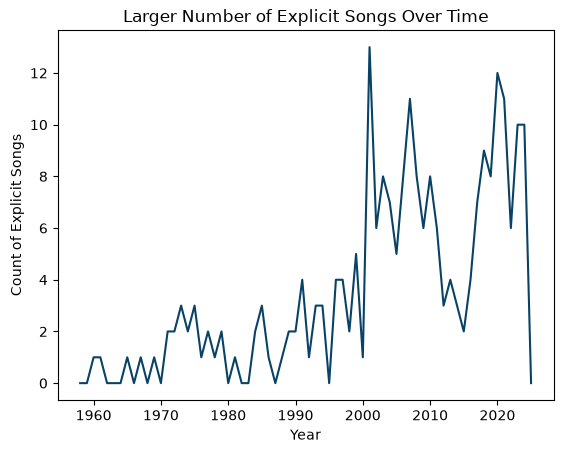

In [54]:
yearly = sns.lineplot(data=ex, x='year', y='explicit', errorbar=None, estimator=sum, color="#084266")
yearly.set_xticks([2,12,22,32,42,52,62])
yearly.set_xlabel("Year")
yearly.set_ylabel("Count of Explicit Songs")
yearly.set_title("Larger Number of Explicit Songs Over Time")
plt.show()

### Explicit Categories

As mentioned above, there is not a column in the dataframe that tells us why a song was marked as explicit. Instead we will use the `lyrics` and `lyrical_topic` to determine the likely reason a song received it's rating.

We will create 4 categories for explicit ratings: sexual content, drug/alcohol content, violence, and profanity.

We begin by looking at the number of unique entries and value counts in the `lyrical_topic` column. Some songs have more than one topic separated by semicolons, so we would need to manipulate the column before using it for accurate counts.

In [25]:
print(ex["lyrical_topic"].nunique())
ex["lyrical_topic"].value_counts()

398


lyrical_topic
Lost Love                             155
Love                                  153
Lust/Sex                              153
Longing for Love                       48
Dancing                                21
                                     ... 
Anger;Bragging                          1
Getting Back Together;Friendship        1
Lust/Sex;Partying;Bragging;Respect      1
Anger;Bragging;Fighting                 1
Love;Death;Longing for Love             1
Name: count, Length: 398, dtype: int64

We only need to categorize songs if they are rated explicit, so we filter out any songs without the explicit rating and save the new dataframe as `exonly`.

In [26]:
exonly = ex[ex['explicit'] == True]
exonly.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
36,Mr. Custer,Larry Verne,1960-10-10T00:00:00Z,1,1,That famous day in history.The men of the 7th ...,War,1960,1960
60,Big Bad John,Jimmy Dean,1961-11-06T00:00:00Z,5,1,Every morning at the mine you could see him ar...,Work;Death,1961,1960
139,(I Can't Get No) Satisfaction,The Rolling Stones,1965-07-10T00:00:00Z,4,1,I can't get no satisfaction.I can't get no sat...,Lust/Sex;Anger;Restlessness,1965,1960
187,Light My Fire,The Doors,1967-07-29T00:00:00Z,3,1,You know that it would be untrue.You know that...,Lust/Sex,1967,1960
217,Honky Tonk Women,The Rolling Stones,1969-08-23T00:00:00Z,4,1,I met a gin soaked barroom queen in Memphis.Sh...,Lust/Sex,1969,1960


Looking again at the `lyrical_topic` column shows there are many less songs now, as expected.

In [27]:
print(exonly["lyrical_topic"].nunique())
exonly["lyrical_topic"].value_counts()

118


lyrical_topic
Lust/Sex                              56
Lost Love                             17
Lost Love;Bad Relationships           10
Bragging                               6
Lust/Sex;Dancing                       5
                                      ..
Bragging;Fame                          1
Infidelity;Lust/Sex;Empowerment        1
Anger;Bragging                         1
Lust/Sex;Partying;Bragging;Respect     1
Anger;Bragging;Fighting                1
Name: count, Length: 118, dtype: int64

We will have two main methods of flagging songs, one that uses lyrical topics and one that use the song lyrics. We created lists of strings to help with tha categorization. 

We have lists of lyrical topics that likely relate to sexual content, drugs/alcohol, and violence. We also have lists of words that likely relate to sexual content or are categorized as slurs/profanity to check against the lyrics.

In [ ]:
# making the lists
sexual_topic = ['Lust/Sex', 'Love', 'Lost Love', 'Masturbation', 'Infidelity', 'Bad Relationships', 'Longing for Love', 'Marriage', 'Getting Back Together']
sexual_words = ['penis', 'vagina', 'tits', 'blowjob', 'boner', 'clit', 'cum', 'pussy']
drug_alcohol_topic = ['Addiction', 'Partying']
violence_topic = ['War', 'Death', 'Fighting', 'Violence', 'Murder', 'Revenge', 'Anger', 'Bad Behavior']
profanity_slur_words = ['ass', 'balls', 'bastard', 'bitch', 'blowjob', 'boner', 'clit', 'cock', 'cum', 'cunt', 'damn', 'dick', 'dyke', 'faggot', 'fuck', 'hell', 'nigger', 'pecker', 'piss', 'pussy', 'shit', 'tits', 'twat', 'whore', 'fucker', 'motherfucker', 'fag', 'fucking', 'damnit']

We created a dataframe with only 5 rows to test the process of categorization on.

In [44]:
# Testing a small group to see if this works
extest = ex.head()
extest

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love,1958,1950
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming,1958,1950
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love,1958,1950
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love,1958,1950
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love,1958,1950


We defined a function `check_topic` that takes in a list of topics, row index, and dataframe then returns a boolean for if any of the topics in the list appear in the row.

In [ ]:
# crete function to check for topic in row
def check_topic(list, row, df):
    """
    
    """
    for topic in list:
        if topic in str(df.iloc[row,6]):
                return True
    return False

# use function to check all topics in each row
sexual_test = []
for row in range(len(extest)):
    sexual_test.append(check_topic(sexual_topic, row, extest))

# see if it correctly categorized
print(sexual_test)

[True, False, True, True, True]


#### Creating columns for explicit reasoning

Now that we know the method above works we will flag the entire `exonly` dataframe.

We created another function similar to `check_topic` that checks the lyrics of each song, which we named `check_lyrics`. We also combined the two functions into `check_topic_and_lyrics` for the categories where we are using both. 

In [ ]:
def check_lyrics(list,row, df):
    """
    
    """
    for word in list:
        if word in str(df.iloc[row,5]):
                return True
    return False

In [ ]:
def check_topic_and_lyrics(topic_list,word_list,row):
    """
    
    """
    for topic in topic_list:
        if topic in str(exonly.iloc[row,6]):
            return True
    for word in word_list:
        if word in str(exonly.iloc[row,5]):
            return True
    return False

We used the functions defined above in conjunction with our lists of keywords to create lists of booleans, then created a new column in our dataframe for each list. Looking at the dataframe again confirms that everything worked as expected.

In [ ]:
sexual = []
for row in range(len(exonly)):
    sexual.append(check_topic_and_lyrics(sexual_topic,sexual_words,row))

drug_alcohol = []
for row in range(len(exonly)):
    drug_alcohol.append(check_topic(drug_alcohol_topic,row))

violence = []
for row in range(len(exonly)):
    violence.append(check_topic(violence_topic,row))

profanity_slur = []
for row in range(len(exonly)):
    profanity_slur.append(check_lyrics(profanity_slur_words,row))


In [38]:
exonly['sexual'] = sexual
exonly['drug_alcohol'] = drug_alcohol
exonly['violence'] = violence
exonly['profanity_slur'] = profanity_slur

exonly.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade,sexual,drug_alcohol,violence,profanity_slur
36,Mr. Custer,Larry Verne,1960-10-10T00:00:00Z,1,1,That famous day in history.The men of the 7th ...,War,1960,1960,False,False,True,False
60,Big Bad John,Jimmy Dean,1961-11-06T00:00:00Z,5,1,Every morning at the mine you could see him ar...,Work;Death,1961,1960,False,False,True,True
139,(I Can't Get No) Satisfaction,The Rolling Stones,1965-07-10T00:00:00Z,4,1,I can't get no satisfaction.I can't get no sat...,Lust/Sex;Anger;Restlessness,1965,1960,True,False,True,False
187,Light My Fire,The Doors,1967-07-29T00:00:00Z,3,1,You know that it would be untrue.You know that...,Lust/Sex,1967,1960,True,False,False,False
217,Honky Tonk Women,The Rolling Stones,1969-08-23T00:00:00Z,4,1,I met a gin soaked barroom queen in Memphis.Sh...,Lust/Sex,1969,1960,True,False,False,False


Now we will create graphs for each of the 4 categories over time.

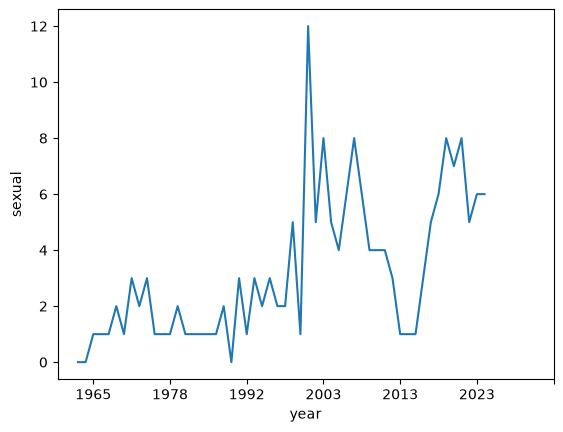

In [39]:
yearly = sns.lineplot(data=exonly, x='year', y='sexual', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

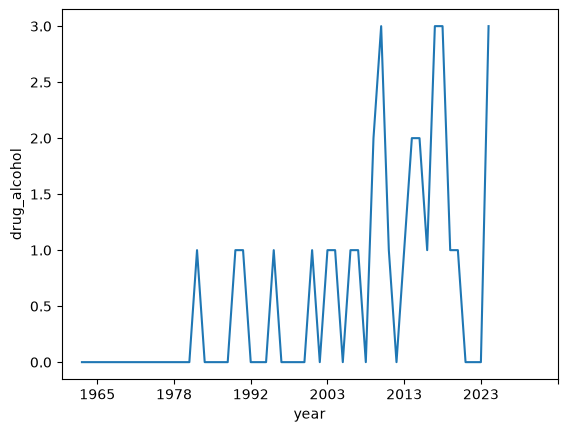

In [40]:
yearly = sns.lineplot(data=exonly, x='year', y='drug_alcohol', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

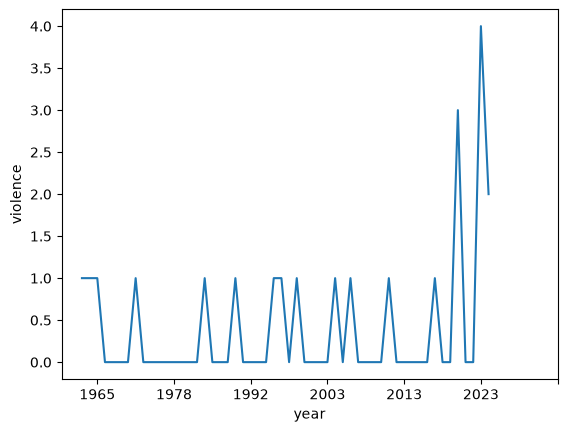

In [41]:
yearly = sns.lineplot(data=exonly, x='year', y='violence', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

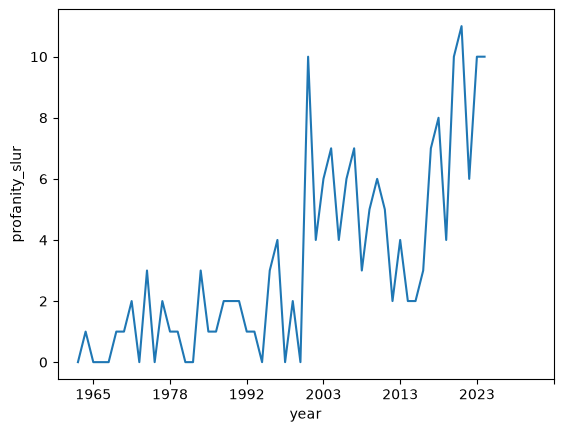

In [42]:
yearly = sns.lineplot(data=exonly, x='year', y='profanity_slur', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

We also created a lineplot with each category to more clearly illustrate relationships between them.

Text(0, 0.5, 'Count')

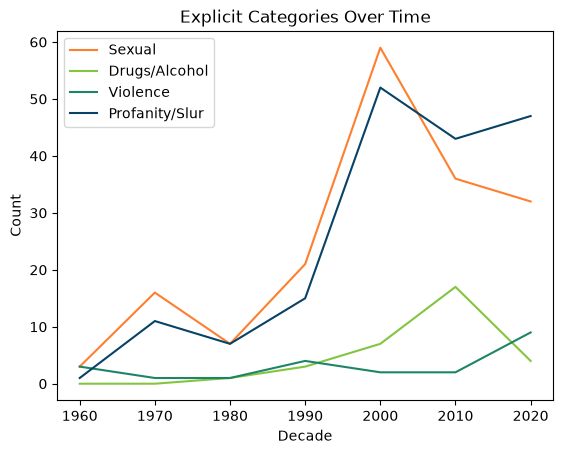

In [98]:
sns.lineplot(data=exonly, x="decade", y="sexual", estimator=sum, errorbar=None, color="#fe7f2d", label="Sexual")
sns.lineplot(data=exonly, x="decade", y="drug_alcohol", estimator=sum, errorbar=None, color="#83c540", label="Drugs/Alcohol")
sns.lineplot(data=exonly, x="decade", y="violence", estimator=sum, errorbar=None, color="#1d8567", label="Violence")
sns.lineplot(data=exonly, x="decade", y="profanity_slur", estimator=sum, errorbar=None, color="#084266", label="Profanity/Slur")
plt.title("Explicit Categories Over Time")
plt.xlabel("Decade")
plt.ylabel("Count")